In [2]:
import pandas as pd

from sklearn.datasets import load_breast_cancer
data=load_breast_cancer()
X=pd.DataFrame(data.data, columns=data.feature_names)
y=pd.Series(data.target, name='target')
print("Data shape:")
print(X.shape)
print("Target shape:")
print(y.shape)
print("First few rows of data:")
print(X.head())
print("Column names:")
print(X.columns.tolist())
print("Target distribution:")
print(y.value_counts())
print("Target distribution percentages:")
print(y.value_counts(normalize=True)*100)


Data shape:
(569, 30)
Target shape:
(569,)
First few rows of data:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension

In [8]:
print("Data types:")
X.info()
print("Missing values:")
print(X.isnull().sum())
print("Total missing values:")
print(X.isnull().sum().sum())
print("Duplicate rows:")
print(X.duplicated().sum())


Data types:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         

In [6]:
print(X.describe().T)

                         count        mean         std         min  \
mean radius              569.0   14.127292    3.524049    6.981000   
mean texture             569.0   19.289649    4.301036    9.710000   
mean perimeter           569.0   91.969033   24.298981   43.790000   
mean area                569.0  654.889104  351.914129  143.500000   
mean smoothness          569.0    0.096360    0.014064    0.052630   
mean compactness         569.0    0.104341    0.052813    0.019380   
mean concavity           569.0    0.088799    0.079720    0.000000   
mean concave points      569.0    0.048919    0.038803    0.000000   
mean symmetry            569.0    0.181162    0.027414    0.106000   
mean fractal dimension   569.0    0.062798    0.007060    0.049960   
radius error             569.0    0.405172    0.277313    0.111500   
texture error            569.0    1.216853    0.551648    0.360200   
perimeter error          569.0    2.866059    2.021855    0.757000   
area error          

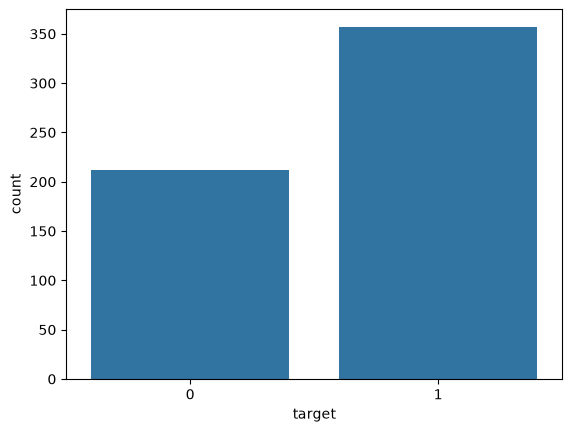

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x=y)
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target distribution:")
print(y_train.value_counts(normalize=True)*100)       
print("Testing target distribution:")
print(y_test.value_counts(normalize=True)*100)

Training data shape: (455, 30)
Testing data shape: (114, 30)
Training target distribution:
target
1    62.637363
0    37.362637
Name: proportion, dtype: float64
Testing target distribution:
target
1    63.157895
0    36.842105
Name: proportion, dtype: float64


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42))
])
pipeline.fit(X_train, y_train)
y_pred=pipeline.predict(X_test)
print("Predictions on test data:")
print(y_pred[:10])  # Display first 10 predictions
print("Actual values:")
print(y_test.values[:10])  # Display first 10 actual values

Predictions on test data:
[0 1 0 1 0 1 1 0 0 0]
Actual values:
[0 1 0 1 0 1 1 0 0 0]


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Model Evaluation Metrics:")
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)
print("Classification Report:")
report = classification_report(y_test, y_pred,target_names=data.target_names)
print(report)


Model Evaluation Metrics:
Accuracy: 0.9825
Precision: 0.9861
Recall: 0.9861
F1-Score: 0.9861
Confusion Matrix:
[[41  1]
 [ 1 71]]
Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

